# E7 · Everything together: eight pendulums, rewired every 2.5 s
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

The capstone of step 1: what passed one experiment at a time (E1 to E6), all at once, on a larger system that keeps changing.

**Where we're at.** Step 1, the capstone. Each piece passed on its own: decomposition (E1), transfer across body counts (E2), gating (E3), detection with non-negativity (E5) and recall (E6).

**Where the system is after the last experiments.** Every test so far used 3 to 5 bodies and one change at a time. Recall beat detection on a ring of 5 with half of its 32 wirings stored (E6).

**Where we want it.** Eight pendulums rewired every few seconds, predicted by maps learned only on 3 and 5 bodies, with each new wiring picked from all 256 possible ones, and predictions within 1.5× of knowing the wiring.

**How this set moves it.** One 30 s run of a ring of 8, rewired every 2.5 s to a random wiring. The binding vertex over the complete bank is compared with known gates, sliding-window detection and a model that never updates. A sweep then varies how often and how the wiring changes, and the noise.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e7")
world = config.world_from(cfg)
p = cfg["e7"]

In [2]:
F.ledger("e7")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | ring | how the springs are wired |
| `n` | 8 | number of bodies |
| `amplitude` | 0.1 | starting swing size (rad) |
| `noise` | 0.01 | measurement noise, fraction of the swing |
| `switch_every` | 50 | steps between rewirings |
| `total_steps` | 600 | steps per switch trial |
| `switch_kind` | pattern | how the wiring changes: a fresh pattern, or one spring |
| `trials` | 20 | trials per condition and seed |
| `horizon` | 20 | how far ahead the nominal world predicts (steps) |
| `windows` | [20, 50] | window lengths (steps) |
| `train_sizes` | [3, 5] | training body counts |
| `train_graphs` | ['path', 'ring'] | training graphs |
| `train_patterns` | 3 | random gate patterns per training graph |
| `train_trajectories` | 10 | trajectories per training configuration |
| `train_steps` | 200 | steps per training trajectory |
| `calibration_steps` | 2000 | steps of the noise calibration run |
| `sweep_every` | [20, 50, 100] | rewiring intervals swept (steps) |
| `sweep_noise` | [0.01, 0.05] | noise levels swept |
| `sweep_kinds` | ['pattern', 'toggle'] | kinds of rewiring swept |
| `sweep_trials` | 10 | runs per swept condition and seed |

## The question

Nothing new is learned here. The step is E2's, learned on 3- and 5-body graphs: $P(g)=I_8\otimes K-L(g)\otimes M$. The binding vertex is E6's, but its bank $G$ now holds every one of the $2^8=256$ wirings of the ring, so whatever the world does, the right answer is stored.

What changes is the cost of switching. Each step the vertex expects to stay with probability $1-h$ and spreads $h$ over the other $C-1$ wirings, with $h=1/50$, the rewiring rate. To move its belief to a new wiring, the evidence has to pay for that prior:

$$\underbrace{\log\frac{(1-h)\,(C-1)}{h}}_{\text{evidence needed to switch}}=\log\frac{0.98\times255}{0.02}\approx 9.4\ \text{nats}$$

The evidence per step is the gap in negative log-likelihood between the old and new wiring, and it grows with how much the springs that changed are stretched:

$$\Delta\mathrm{NLL}(t)\approx\tfrac12\Big\|\big(\underbrace{(L_{\text{new}}-L_{\text{old}})}_{\text{the springs that changed}}\otimes M\big)\,x(t)\Big\|^2_{\Sigma^{-1}}$$

So re-locking should take a few steps when the changed springs are well stretched, and longer when they are barely stretched. Detection has no prior to pay, but it waits for its window to fill with the new wiring.

**Prediction.** Recall re-locks in a few steps, as in E6, so the right wiring is in force at least 90% of the time when the wiring changes every 50 steps. Detection is held back by its window (about 20 steps for a 20-step window). Predictions one second ahead stay within 1.5× of those made with known gates.
**Pass if** the right wiring is in force on at least 90% of steps, the median re-lock is at most 5 steps and at least 5× faster than the best detector, and the deviation one second ahead is within 1.5× of known gates.

In [3]:
runs = F.ensure_results("e7")

e7: 3 seeds loaded (code 044c98d, run 2026-11-25T21:54:57+00:00)


## The world: a ring of 8, and every wiring it can take

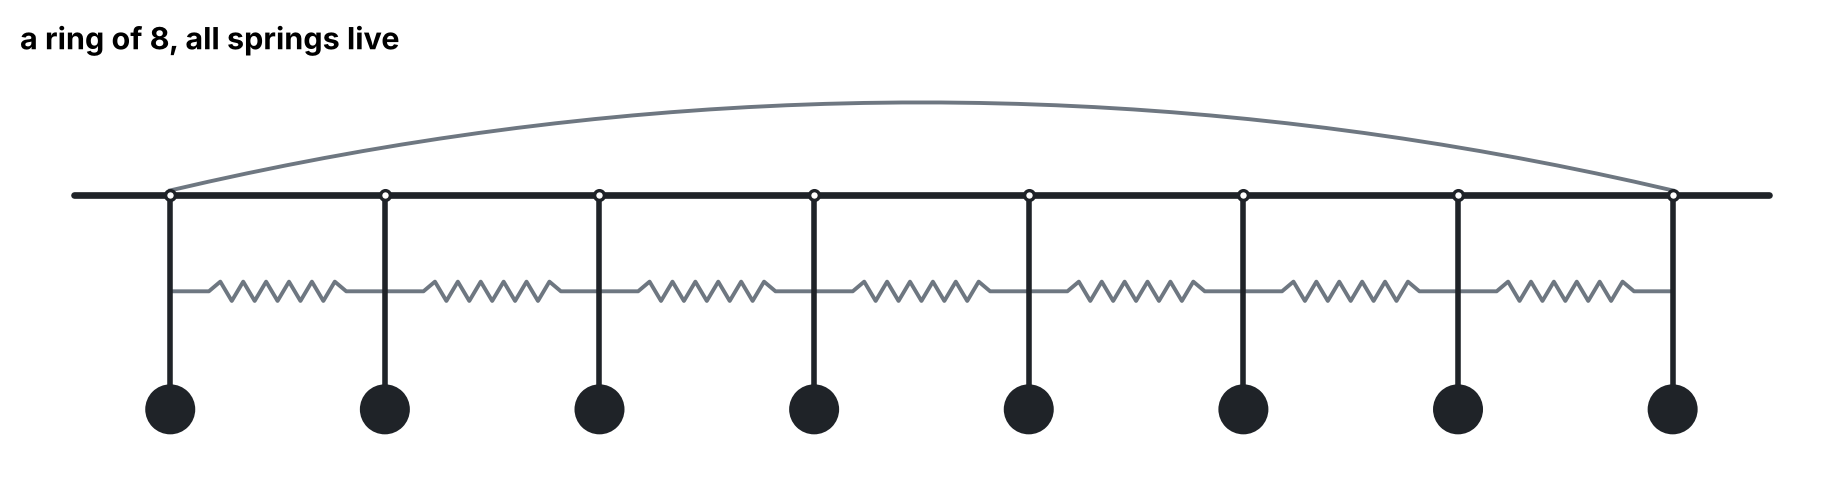

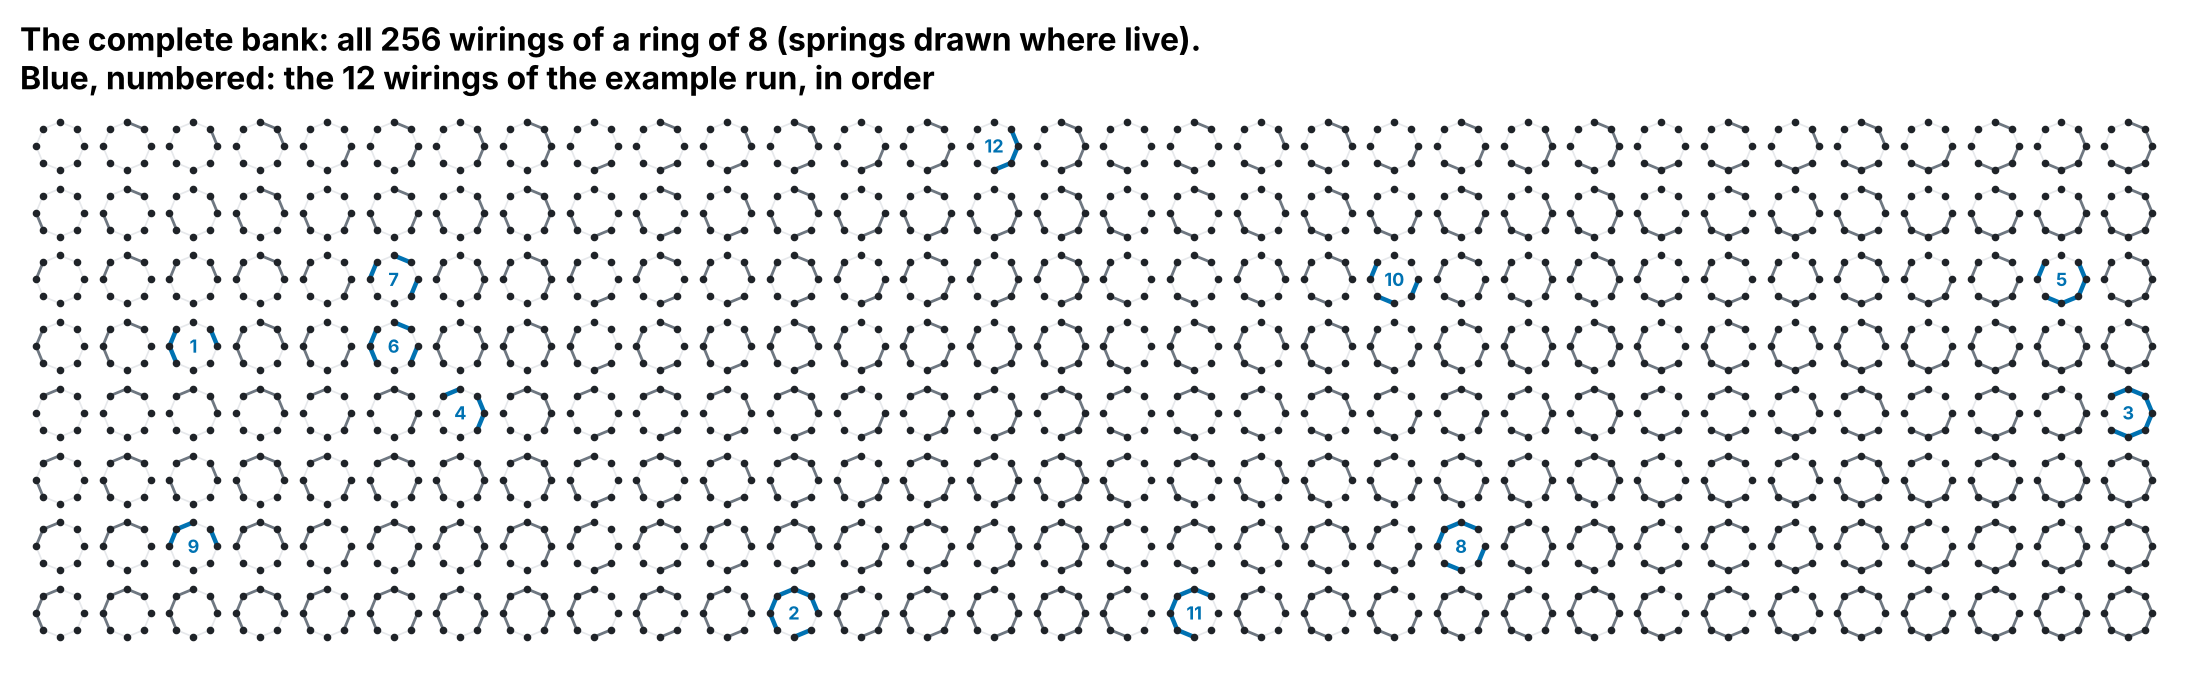

In [4]:
F.schematics([("a ring of 8, all springs live", 8, graphs.ring(8), None)], cols=1);
F.e7_bank(runs[0]);

## Nominal vs actual: one second ahead

Here the nominal world is the prediction made **one second earlier**, from what was measured then, with the wiring the method believed then. Even with known gates, a prediction made just before a rewiring misses after it; what differs between methods is how quickly they recover. Blue dashed springs mark where the wiring behind the prediction differs from the actual one. Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time.

In [5]:
a = runs[0]["arrays"]
tol = 0.05 * p["amplitude"]
sw = list(range(p["switch_every"], p["total_steps"], p["switch_every"]))
for name, label in (("recall", "Binding vertex over the complete bank"), ("detect-20", "Sliding detection, 20-step window")):
    display(viz.player(a["theta_act"], a[f"theta_nom_{name}"], graphs.ring(8), a["gates_act"], dt=world.dt, tol=tol,
                       nominal_gates=a[f"gates_nom_{name}"], switch_steps=sw,
                       title=f"{label}: the world as predicted one second earlier",
                       subtitle="Ring of 8, rewired every 2.5 s (orange marks). Tolerance: 5% of the 0.1 rad swing."))

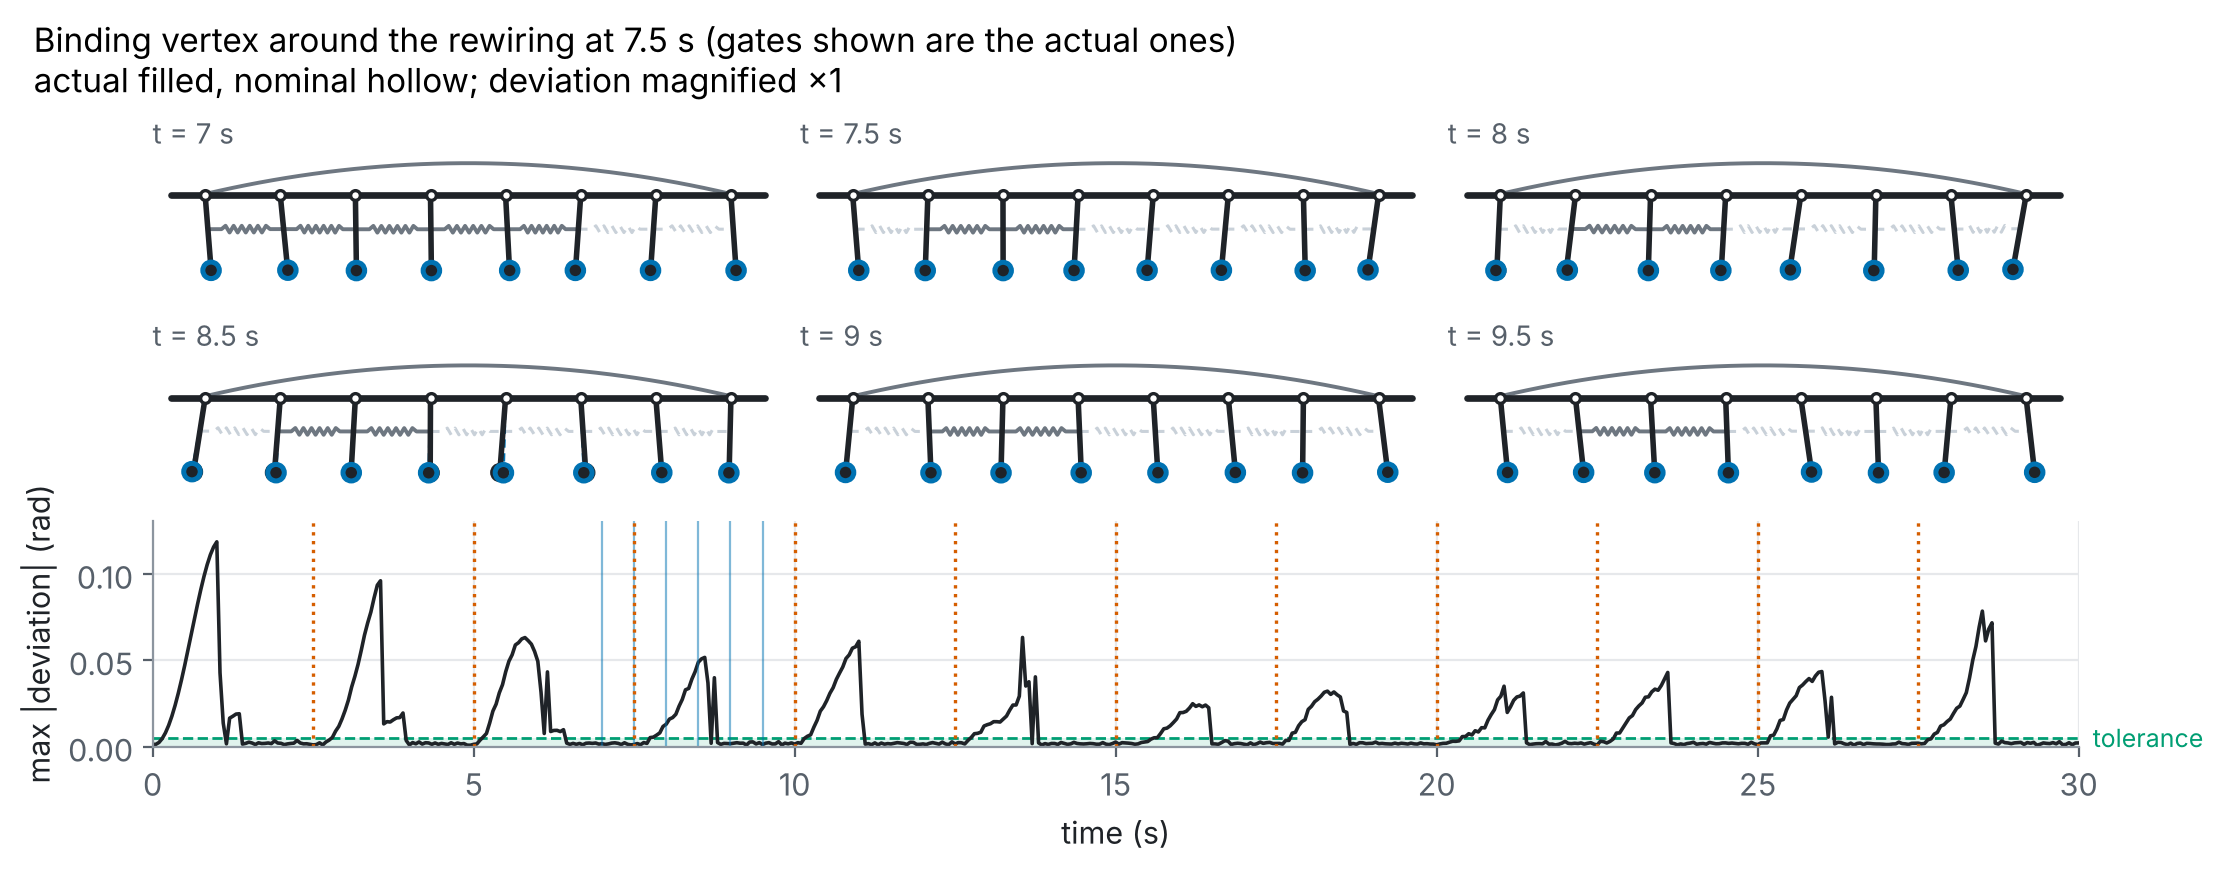

In [6]:
viz.film_strip(a["theta_act"], a["theta_nom_recall"], graphs.ring(8), a["gates_act"], dt=world.dt, tol=tol,
               times=[7.0, 7.5, 8.0, 8.5, 9.0, 9.5], switch_steps=sw,
               title="Binding vertex around the rewiring at 7.5 s (gates shown are the actual ones)");

## Tracking the wiring

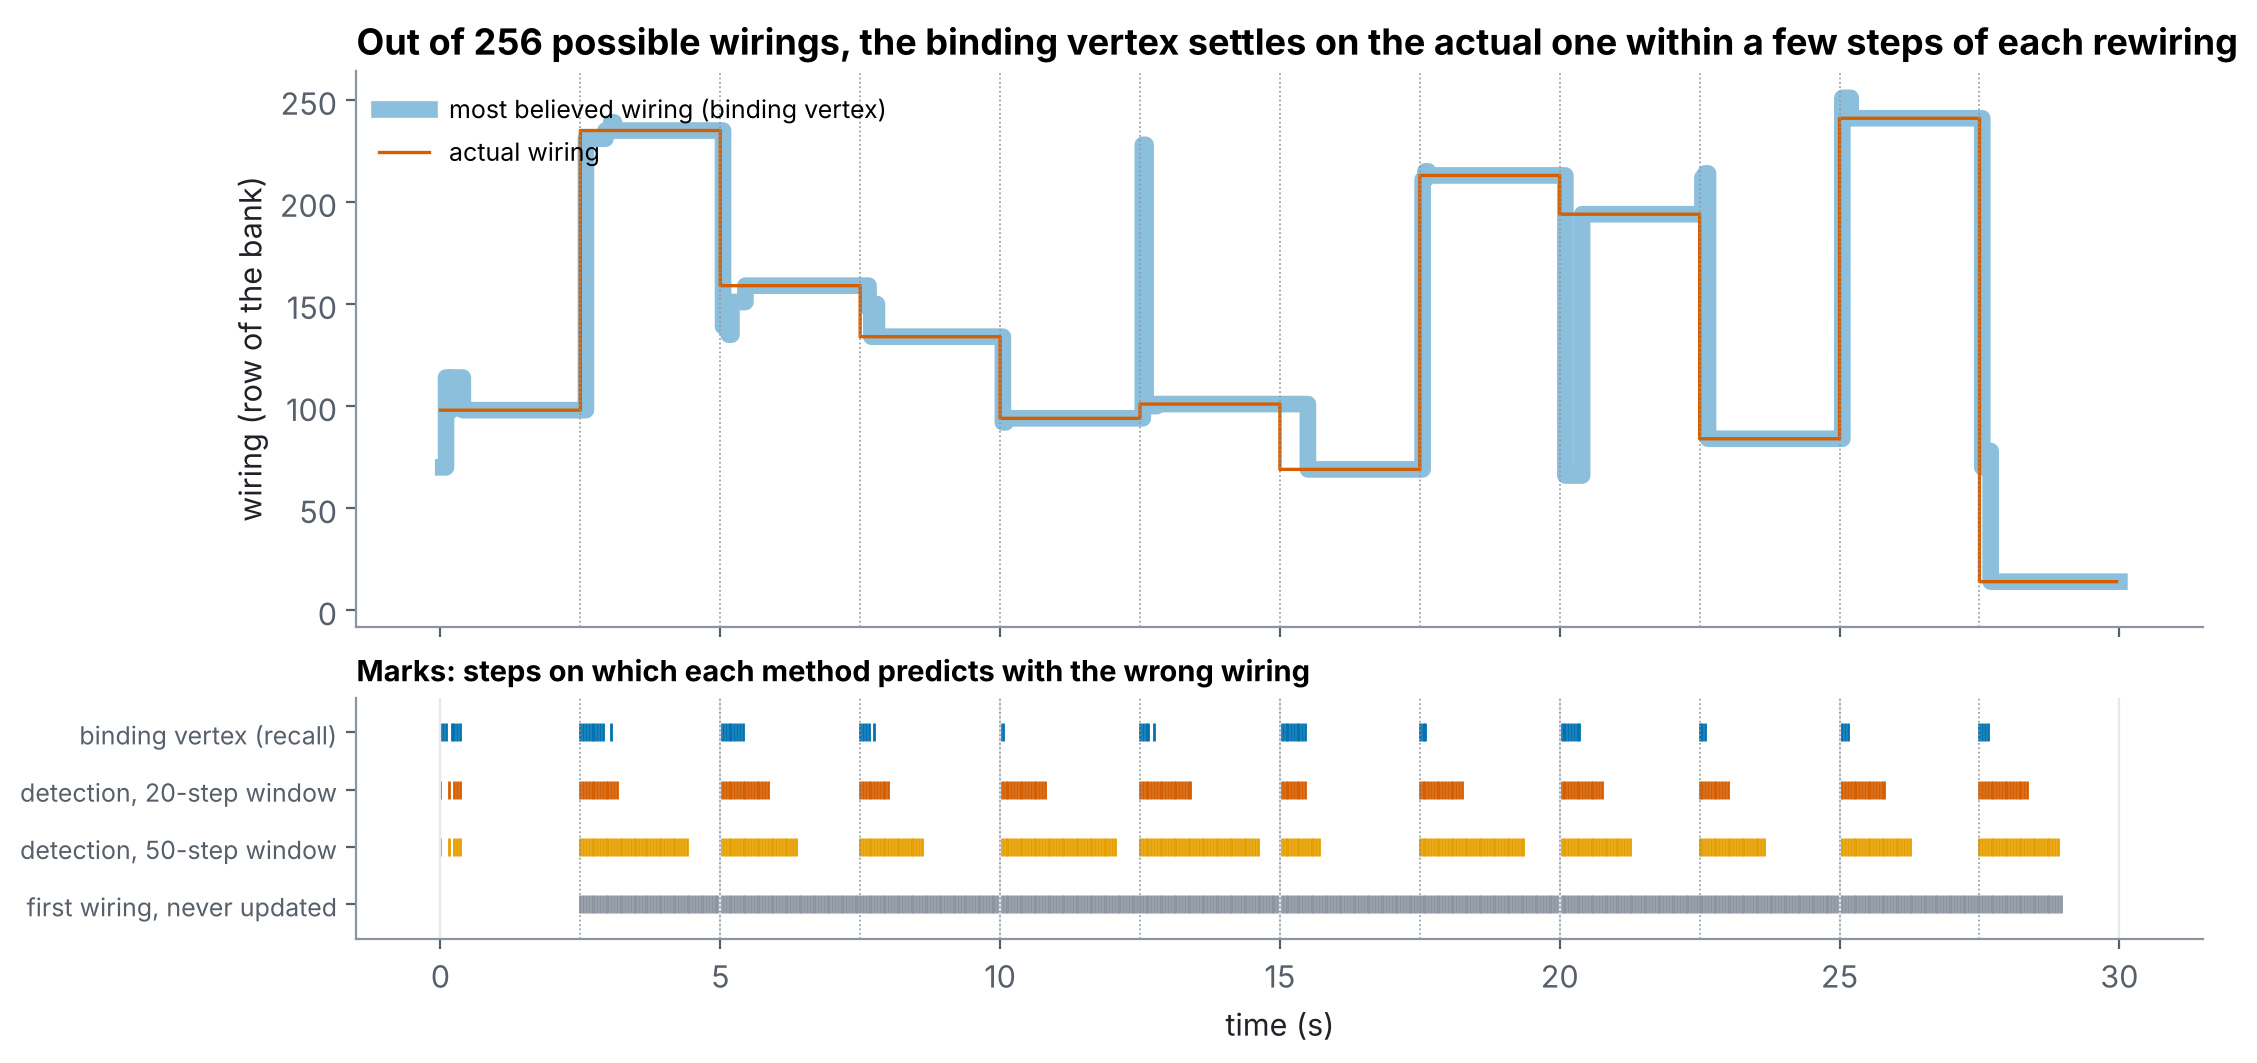

In [7]:
F.e7_timeline(runs[0], world, p['switch_every']);

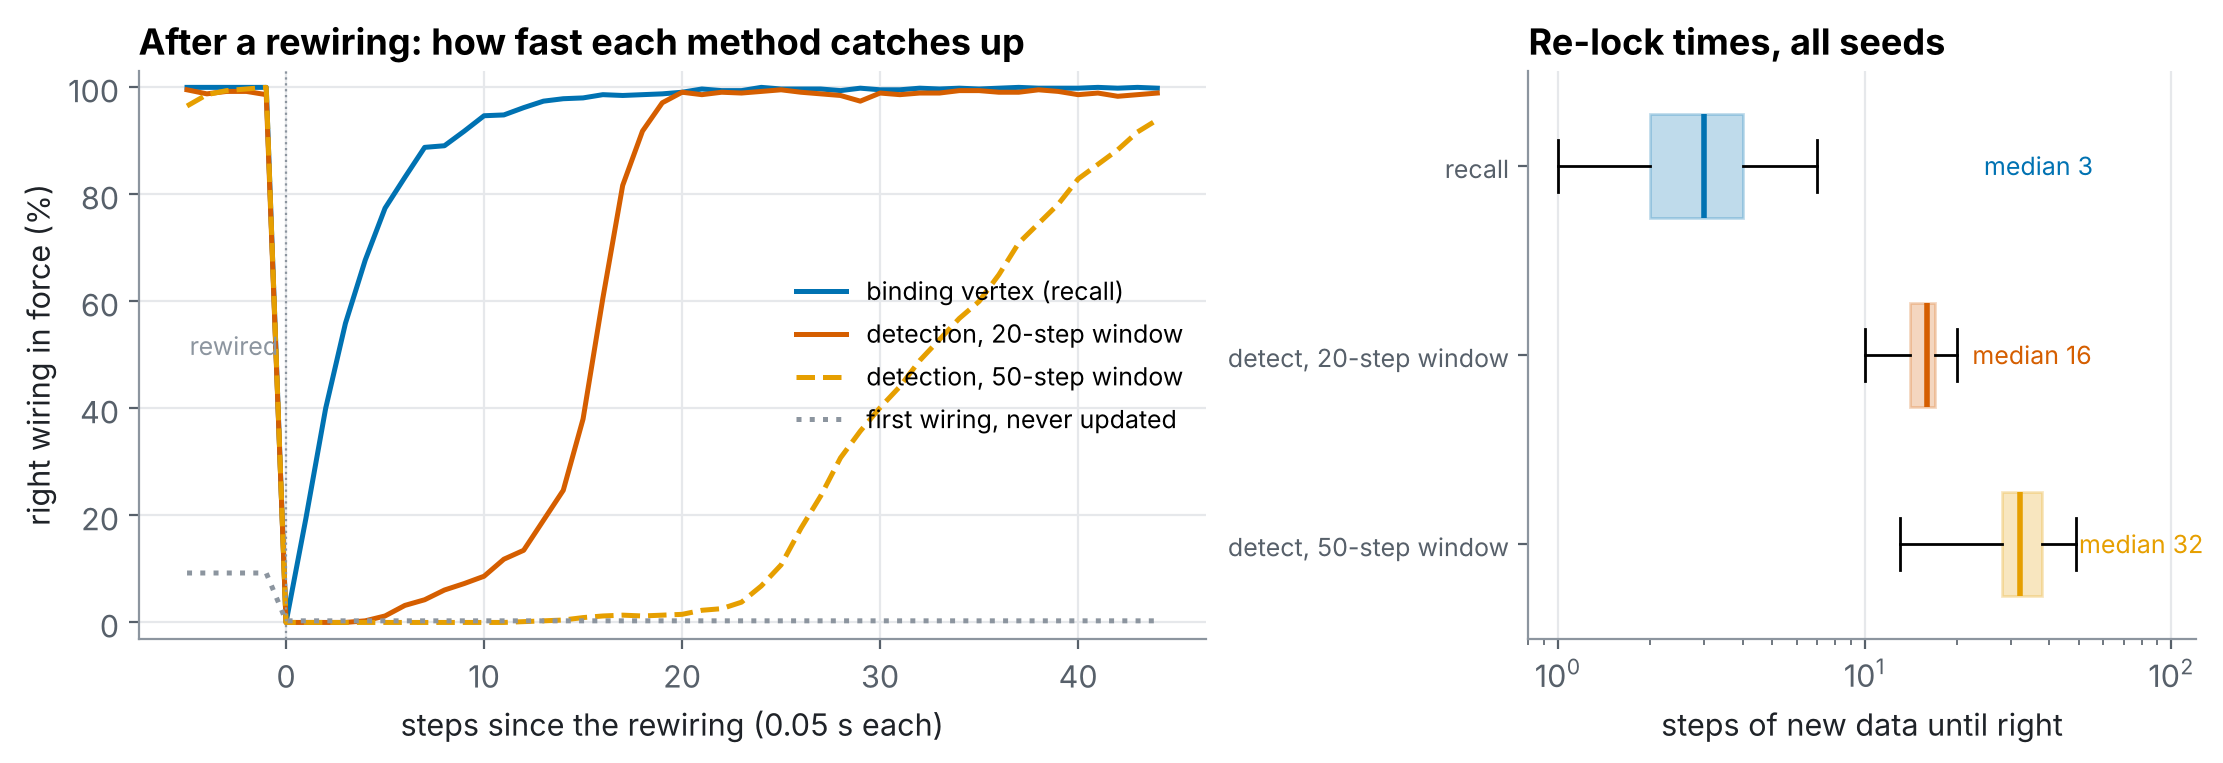

In [8]:
F.e7_event(runs);

In [9]:
mm = [r["metrics"] for r in runs]
c = lambda k: [x["correct"][k] for x in mm]
rl = lambda k: [x["relock_median"][k] for x in mm]
F.say(f"The binding vertex has the right wiring in force on {F.spread([100 * v for v in c('recall')])}% of steps and "
      f"re-locks in a median of {F.spread(rl('recall'))} steps. Detection with a 20-step window manages "
      f"{F.spread([100 * v for v in c('detect-20')])}% and {F.spread(rl('detect-20'))} steps; with a 50-step window, "
      f"{F.spread([100 * v for v in c('detect-50')])}% and {F.spread(rl('detect-50'))} steps. Each window has to fill with "
      "the new wiring before detection can see it; the vertex only has to collect about 9 nats of evidence.")

> **Finding.** The binding vertex has the right wiring in force on 91.6 (90.8 to 92.6)% of steps and re-locks in a median of 3 (3 to 3) steps. Detection with a 20-step window manages 70.6 (69.8 to 71)% and 16 (16 to 16) steps; with a 50-step window, 38.2 (37.5 to 39)% and 32.5 (32 to 33) steps. Each window has to fill with the new wiring before detection can see it; the vertex only has to collect about 9 nats of evidence.

## What it does to prediction

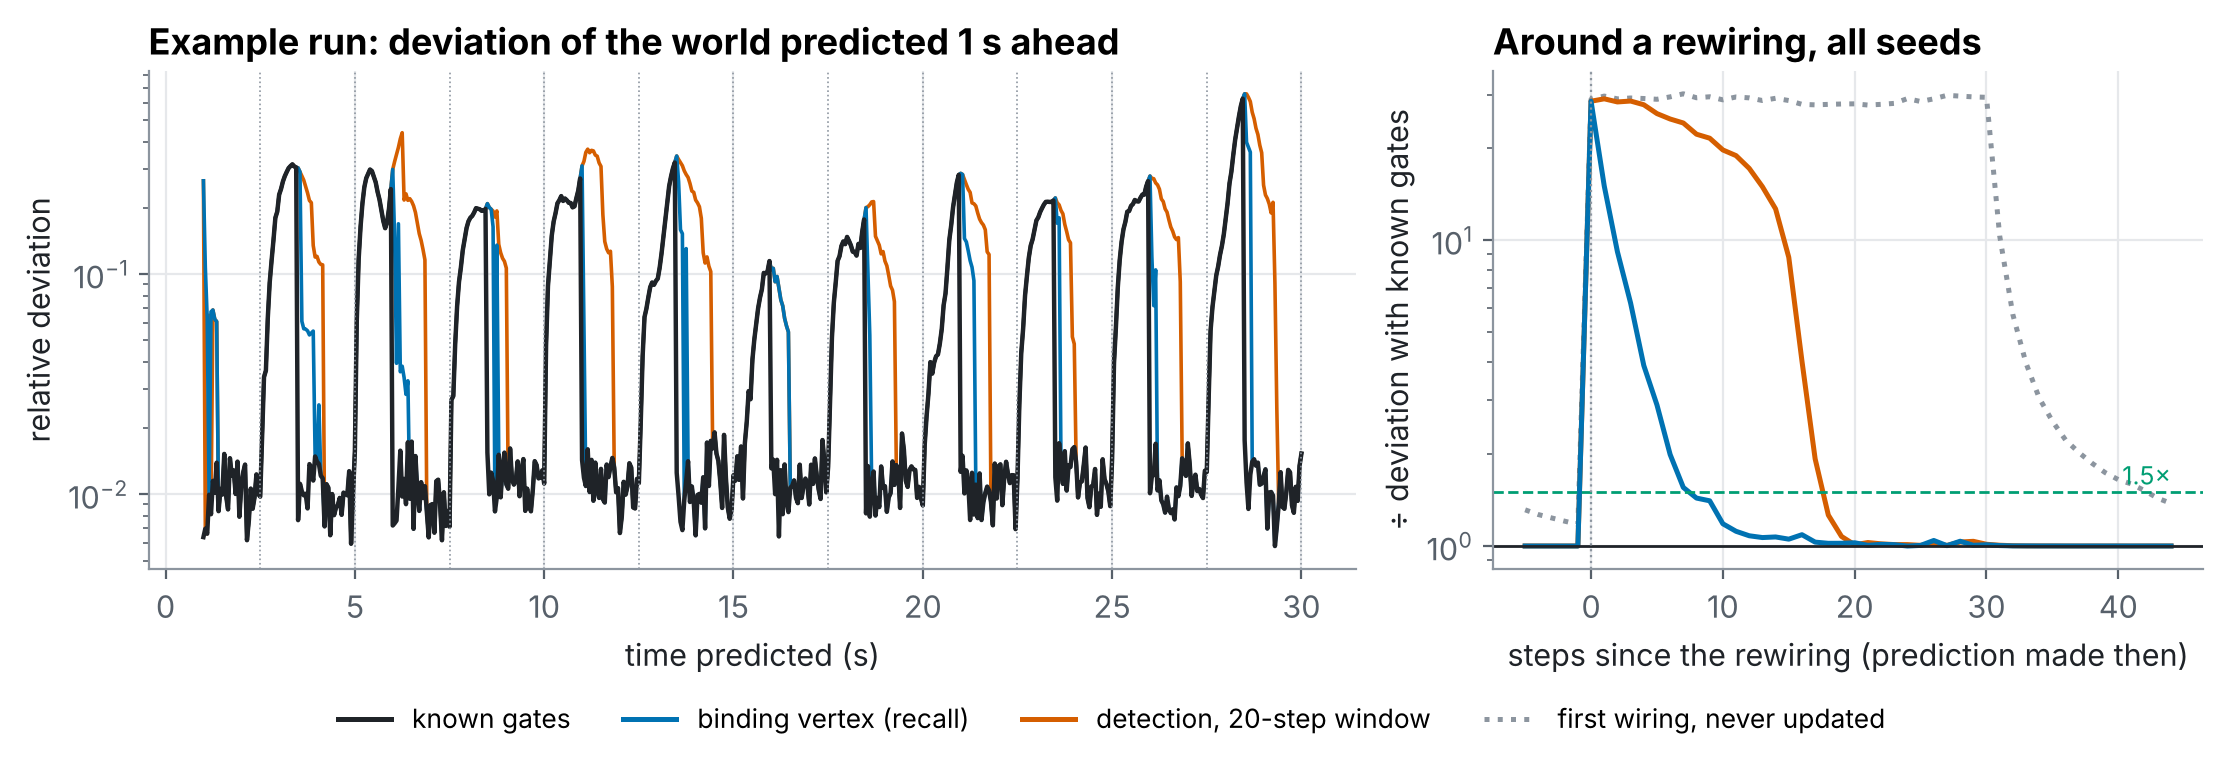

In [10]:
F.e7_deviation(runs[0], runs, world, p['switch_every'], p['horizon']);

In [11]:
d = lambda k: [x["dev_ratio"][k] for x in mm]
offs = runs[0]["arrays"]["aligned_offsets"]
back = np.mean([r["arrays"]["aligned_dev_recall"] for r in runs], 0)
back_at = int(offs[(offs > 0) & (back < 1.5)][0])
F.say(f"One second ahead, the binding vertex's predictions deviate {F.spread(d('recall'))}× as much as predictions made "
      f"with known gates, averaged over the run. Detection with a 20-step window reaches {F.spread(d('detect-20'))}×, and a "
      f"model that never updates its wiring {F.spread(d('stale'))}×. Right after a rewiring every method is about as wrong "
      "as the others, because none of them has seen the new wiring yet; the vertex is back within 1.5× of known gates "
      f"{back_at} steps later.")

> **Finding.** One second ahead, the binding vertex's predictions deviate 1.18 (1.18 to 1.18)× as much as predictions made with known gates, averaged over the run. Detection with a 20-step window reaches 1.88 (1.85 to 1.92)×, and a model that never updates its wiring 3.54 (3.41 to 3.67)×. Right after a rewiring every method is about as wrong as the others, because none of them has seen the new wiring yet; the vertex is back within 1.5× of known gates 8 steps later.

## Why some rewirings are slow to see

A spring only shows itself through the force it carries, and that force is proportional to its stretch $\theta_v-\theta_u$. When the springs that changed connect pendulums that happen to swing together, they carry almost no force, the evidence per step is small, and the vertex needs more steps to pay its 9.4-nat prior.

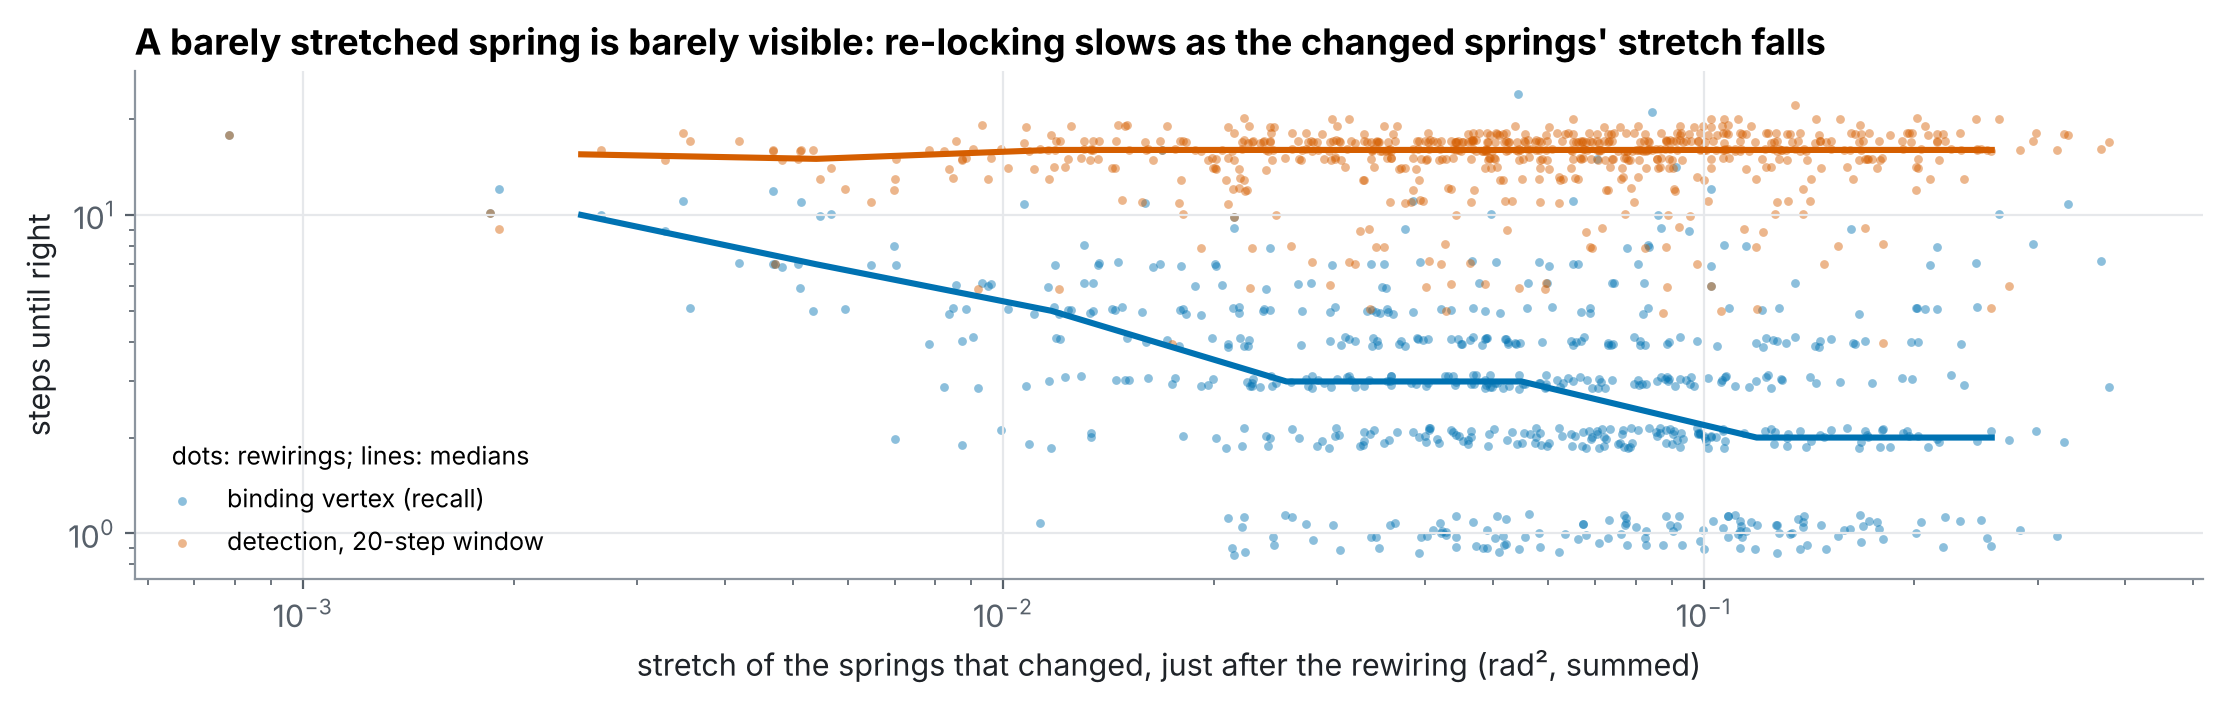

In [12]:
F.e7_visibility(runs);

In [13]:
ev = [e for x in mm for e in x["events"]]
st = np.array([e["stretch"] for e in ev])
rr = np.array([e["relock_recall"] if e["relock_recall"] is not None else np.nan for e in ev], float)
lo, hi = np.nanpercentile(st, [33, 67])
F.say(f"For the third of rewirings whose changed springs were least stretched, the vertex needed a median of "
      f"{viz.fmt(np.nanmedian(rr[st <= lo]))} steps; for the most stretched third, {viz.fmt(np.nanmedian(rr[st >= hi]))}. "
      "Detection takes about 16 steps either way, because its window, not the evidence, sets its pace.")

> **Finding.** For the third of rewirings whose changed springs were least stretched, the vertex needed a median of 4 steps; for the most stretched third, 2. Detection takes about 16 steps either way, because its window, not the evidence, sets its pace.

## How far it stretches

The sweep repeats the run with the wiring changing every 1, 2.5 or 5 s, by a whole new pattern or by one spring at a time, at 1% and 5% noise. It adds a second vertex whose prior expects single-spring flips: it spreads $h$ over the 8 wirings one spring away instead of all 255.

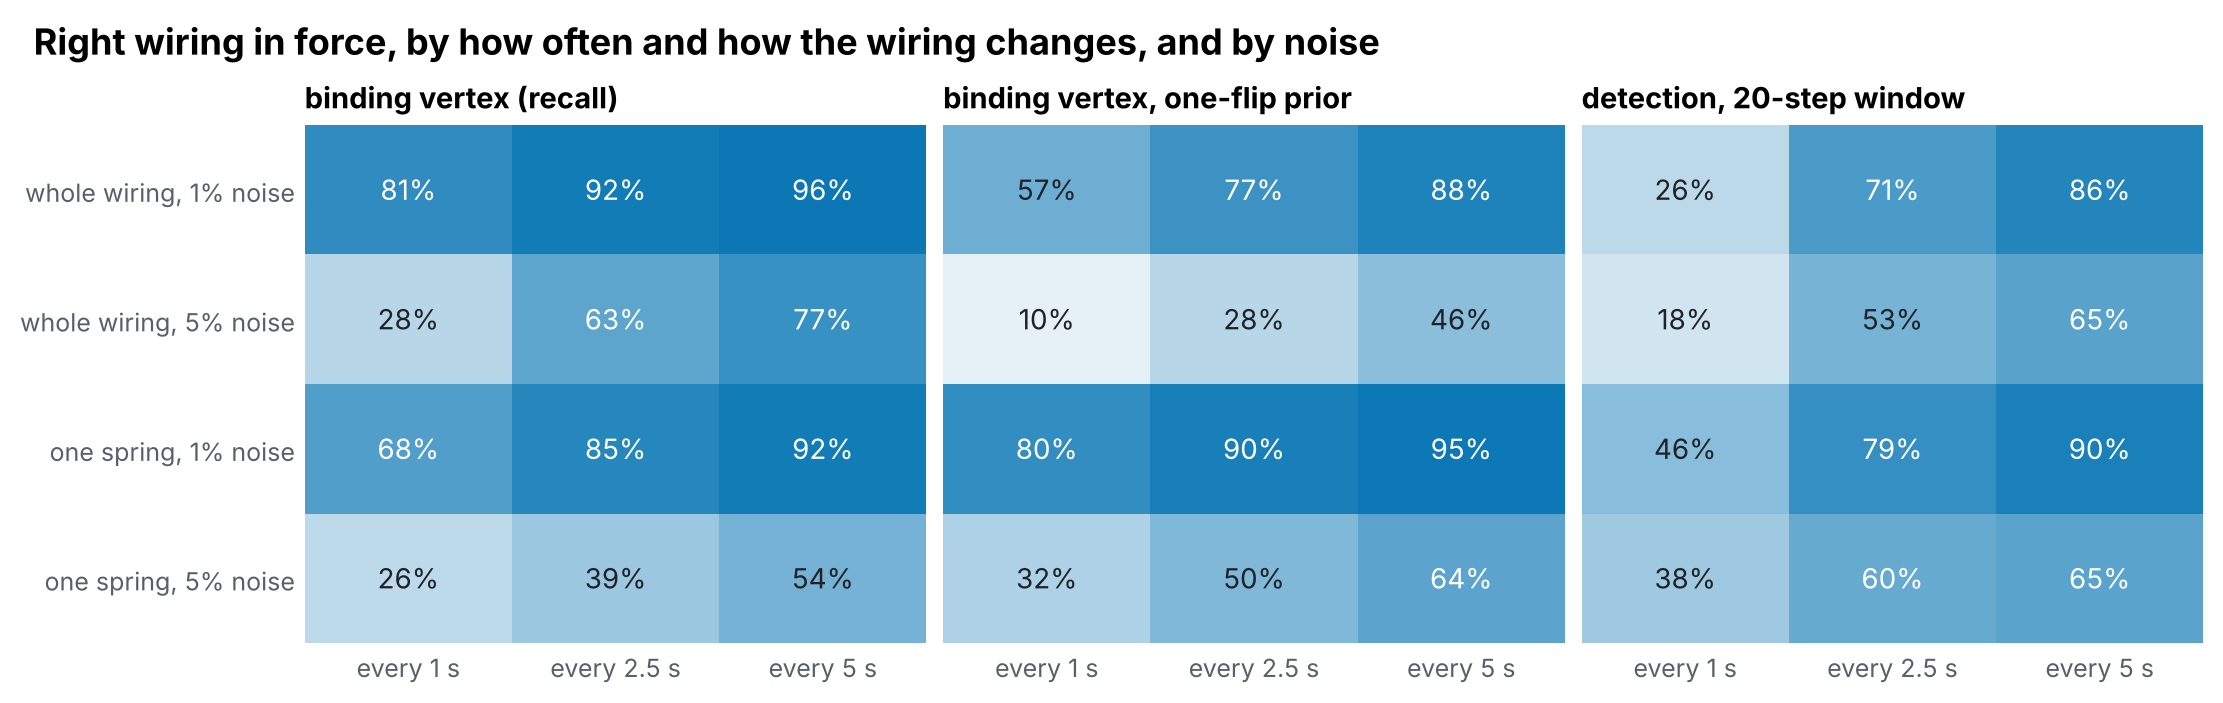

In [14]:
F.e7_sweep(runs);

In [15]:
sw_ = lambda kind, noise, every, k: float(np.mean([next(cc for cc in x["sweep"] if cc["kind"] == kind and cc["noise"] == noise
                                                          and cc["every"] == every)["correct"][k] for x in mm]))
F.say(f"The vertex wins where its prior matches the world. With whole-pattern rewiring every 2.5 s it is right "
      f"{viz.pct(sw_('pattern', 0.01, 50, 'recall'))} of the time at 1% noise and {viz.pct(sw_('pattern', 0.05, 50, 'recall'))} at 5%, "
      f"against {viz.pct(sw_('pattern', 0.01, 50, 'detect-20'))} and {viz.pct(sw_('pattern', 0.05, 50, 'detect-20'))} for detection. "
      f"When one spring flips at a time under 5% noise it falls behind: {viz.pct(sw_('toggle', 0.05, 50, 'recall'))} against "
      f"{viz.pct(sw_('toggle', 0.05, 50, 'detect-20'))}. A prior that expects single flips recovers part of the gap "
      f"({viz.pct(sw_('toggle', 0.05, 50, 'recall-flip'))}) but collapses on whole-pattern rewiring "
      f"({viz.pct(sw_('pattern', 0.05, 50, 'recall-flip'))} at 5% noise). How the wiring tends to change is itself something "
      "to learn, which is step 3's question: structure that generates the bank's transitions rather than a fixed prior.")

> **Finding.** The vertex wins where its prior matches the world. With whole-pattern rewiring every 2.5 s it is right 92% of the time at 1% noise and 63% at 5%, against 71% and 53% for detection. When one spring flips at a time under 5% noise it falls behind: 39% against 60%. A prior that expects single flips recovers part of the gap (50%) but collapses on whole-pattern rewiring (28% at 5% noise). How the wiring tends to change is itself something to learn, which is step 3's question: structure that generates the bank's transitions rather than a fixed prior.

## Inspection report

In [16]:
mean = lambda xs: float(np.mean(xs))
speed = mean(rl("detect-20")) / mean(rl("recall"))
viz.inspection_report([
    {"characteristic": "Right wiring in force (binding vertex)", "nominal": mean(c("recall")), "tolerance": "≥ 0.90",
     "status": "in" if mean(c("recall")) >= 0.9 else "out"},
    {"characteristic": "Median re-lock (binding vertex), steps", "nominal": mean(rl("recall")), "tolerance": "≤ 5",
     "status": "in" if mean(rl("recall")) <= 5 else "out"},
    {"characteristic": "Re-lock speed-up over the best detector", "nominal": speed, "tolerance": "≥ 5×",
     "status": "in" if speed >= 5 else "out"},
    {"characteristic": "Deviation 1 s ahead ÷ known gates (binding vertex)", "nominal": mean(d("recall")), "actual": 1.0,
     "deviation": mean(d("recall")) - 1, "tolerance": 0.5},
    {"characteristic": "Deviation 1 s ahead ÷ known gates (detection, 20 steps)", "nominal": mean(d("detect-20")), "actual": 1.0,
     "deviation": mean(d("detect-20")) - 1, "tolerance": 0.5},
    {"characteristic": "One spring flips, 5% noise: right wiring, vertex vs detection",
     "nominal": f"{viz.pct(sw_('toggle', 0.05, 50, 'recall'))} vs {viz.pct(sw_('toggle', 0.05, 50, 'detect-20'))}",
     "tolerance": "finding", "status": None},
], title="Everything together, means over seeds (main condition: whole-pattern rewiring every 2.5 s, 1% noise)")

**Everything together, means over seeds (main condition: whole-pattern rewiring every 2.5 s, 1% noise)**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| Right wiring in force (binding vertex) | 0.9163 | — | — | ≥ 0.90 | ✓ **in** |
| Median re-lock (binding vertex), steps | 3 | — | — | ≤ 5 | ✓ **in** |
| Re-lock speed-up over the best detector | 5.333 | — | — | ≥ 5× | ✓ **in** |
| Deviation 1 s ahead ÷ known gates (binding vertex) | 1.18 | 1 | 0.1799 | ±0.5 | ✓ **in** |
| Deviation 1 s ahead ÷ known gates (detection, 20 steps) | 1.884 | 1 | 0.8835 | ±0.5 | △ **near** |
| One spring flips, 5% noise: right wiring, vertex vs detection | 39% vs 60% | — | — | finding | — |

## Log

In [17]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `044c98d` | 2026-11-25T21:54:57+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `044c98d` | 2026-11-25T21:54:58+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `044c98d` | 2026-11-25T21:55:15+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |